In [1]:
#read in gene vs disease data
import pandas as pd
import scipy as sp
import numpy as np
from lightfm import cross_validation
from lightfm.evaluation import precision_at_k
from lightfm.evaluation import recall_at_k
from lightfm.evaluation import auc_score
from lightfm import LightFM
import matplotlib.pyplot as plt
import pickle

tsv_file = open("curated_gene_disease_associations.tsv")
df = pd.read_csv(tsv_file, delimiter="\t")

/Users/ctrader/opt/anaconda3/envs/lightfm/lib/python3.8/site-packages/lightfm/_lightfm_fast.py:9: UserWarning: LightFM was compiled without OpenMP support. Only a single thread will be used.
  warnings.warn(


In [2]:
df

,geneId,geneSymbol,DSI,DPI,diseaseId,diseaseName,diseaseType,diseaseClass,diseaseSemanticType,score,EI,YearInitial,YearFinal,NofPmids,NofSnps,source
0,1,A1BG,0.700,0.538,C0019209,Hepatomegaly,phenotype,C23;C06,Finding,0.30,1.000,2017.0,2017.0,1,0,CTD_human
1,1,A1BG,0.700,0.538,C0036341,Schizophrenia,disease,F03,Mental or Behavioral Dysfunction,0.30,1.000,2015.0,2015.0,1,0,CTD_human
2,2,A2M,0.529,0.769,C0002395,Alzheimer's Disease,disease,C10;F03,Disease or Syndrome,0.50,0.769,1998.0,2018.0,3,0,CTD_human
3,2,A2M,0.529,0.769,C0007102,Malignant tumor of colon,disease,C06;C04,Neoplastic Process,0.31,1.000,2004.0,2019.0,1,0,CTD_human
4,2,A2M,0.529,0.769,C0009375,Colonic Neoplasms,group,C06;C04,Neoplastic Process,0.30,1.000,2004.0,2004.0,1,0,CTD_human
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84033,109580095,HBB-LCR,0.743,0.115,C0002875,Cooley's anemia,disease,C16;C15,Disease or Syndrome,0.30,NaN,NaN,NaN,0,0,CTD_human
84034,109580095,HBB-LCR,0.743,0.115,C0005283,beta Thalassemia,disease,C16;C15,Disease or Syndrome,0.30,NaN,NaN,NaN,0,0,CTD_human
84035,109580095,HBB-LCR,0.743,0.115,C0019025,Hemoglobin F Disease,disease,C16;C15,Disease or Syndrome,0.30,NaN,NaN,NaN,0,0,CTD_human
84036,109580095,HBB-LCR,0.743,0.115,C0085578,Thalassemia Minor,disease,C16;C15,Disease or Syndrome,0.30,NaN,NaN,NaN,0,0,CTD_human


In [3]:
#creating df with gene, disease, and association score
gd_df = df[['geneId', 'diseaseId', 'score']]

In [4]:
#finding unique genes and diseases
geneId_values = np.unique(gd_df['geneId'].values)
diseaseId_values = np.unique(gd_df['diseaseId'].values)

In [5]:
#Creating sparse matrix from csv formatted data
gd_matrix = pd.DataFrame(index = diseaseId_values, columns = geneId_values)

for disease in diseaseId_values:
    disease_df = gd_df[gd_df['diseaseId']==disease].set_index('geneId')
    gd_matrix.loc[disease] = disease_df['score']
    
gd_np = gd_matrix.to_numpy()
gd_np = np.array(gd_np, dtype=float)
gd_np[np.isnan(gd_np)] = 0
gd_coo = sp.sparse.coo_matrix(gd_np)

In [6]:
#splitting data into train and test and storing in data with geneIds
(train, test) = cross_validation.random_train_test_split(gd_coo, test_percentage=0.2, random_state=None)
data = {'train': train, 'test': test, 'gene_ids' : geneId_values}

In [7]:
#creating model
model = LightFM(loss='warp')

In [8]:
#training model
model.fit(data['train'], epochs=100, num_threads=2)

In [9]:
# measure AUC score
auc = auc_score(model, data['test']).mean()
print(auc)

0.8315853


In [10]:
# measure precision/recall @ k for k=1:50
test_precision = []
test_recall = []
train_precision = []
train_recall = []

for i in [15]:
    test_precision.append(precision_at_k(model, data['test'], k=i).mean())
    test_recall.append(recall_at_k(model, data['test'], k=i).mean())
    train_precision.append(precision_at_k(model, data['train'], k=i).mean())
    train_recall.append(recall_at_k(model, data['train'], k=i).mean())

In [18]:
# recreating precision function (not finished)
n_diseases, n_genes = data['train'].shape
k=15
test_dense = data['train'].toarray()
precision = []
recall = []
for i in range(n_diseases):
    results = np.where(test_dense[i, :]==1)
    results = set(results[0])
    scores = model.predict(i, np.arange(n_genes))
    top_genes = np.argsort(-scores)
    k_predictions = top_genes[:k]
    counter  = 0
    for j in k_predictions:
        if j in results:
            counter += 1
    precision.append(counter/k)
    if len(results) > 0:
        recall.append(counter/len(results))
    else:
        recall.append(0)
        
print(np.array(precision).mean())
print(precision_at_k(model, data['train'], k=15, num_threads=1).mean())

2
6
2
2
3
2
2
2
2
2


Text(0.5, 1.0, 'Precision-Recall Curves for Disease vs Gene LightFM model')

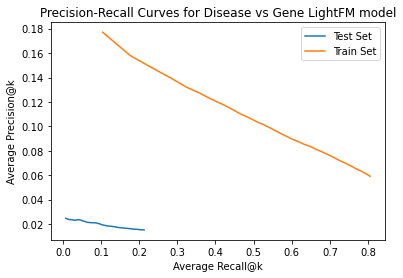

In [12]:
#Plot precision-recall curves for train and test data
plt.plot(test_recall, test_precision)
plt.plot(train_recall, train_precision)
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set', 'Train Set'])
plt.title('Precision-Recall Curves for Disease vs Gene LightFM model')
plt.savefig('Precision_Recall_Curves_for_Disease_vs_Gene_LightFM_model')

In [13]:
pickle_out_model = open('gd_model100.pickle', 'wb')
pickle.dump(model, pickle_out_model)
pickle_out_model.close()

pickle_out_data = open('gd_data100.pickle', 'wb')
pickle.dump(data, pickle_out_data)
pickle_out_data.close()

In [51]:
#function to recommend genes for a given disease. Takes in the model, data, and a list of
#diseases for genes to be recommend for. For each disease, prints out known associated genes
#and a list of recommended genes. Function modeled after tutorial 3, 'Recommendation Systems
#- Learn Python for Data Science' on LightFM github. 

def sample_recommendation(model, data, diseases):
    
    #number of diseases and genes in training dataset
    n_diseases, n_genes = data['train'].shape
    
    #generate gene recommendations for each disease
    for disease in diseases:
        disease_id = df[df['diseaseName'] == disease]['diseaseId'].tolist()[0]
        disease_id_num = list(diseaseId_values).index(disease_id)
        #genes known to relate to the disease
        known_positives = data['gene_ids'][data['train'].tocsr()[disease_id_num].indices]
#         print(known_positives)
        
        #genes model predicts that relate to disease
        scores = model.predict(disease_id_num, np.arange(n_genes))
        print(scores)
#         print(np.argsort(-scores))
#         print(max(np.argsort(-scores)))
        #rank from most related to least
        top_genes = data['gene_ids'][np.argsort(-scores)]
        
        #print results
        print('Disease: ' + disease + ' (' + str(disease_id_num) +')')
        print('   Known Positives:')
        
        known_pos = []
        for gene in known_positives[:]:
            x = df[df['geneId'] == gene]['geneSymbol'].tolist()[0]
            known_pos.append(x)
            print('      %s' % x)
        
        print()
        print('   Recommended:')
        for gene in top_genes[:25]:
            x = df[df['geneId'] == gene]['geneSymbol'].tolist()[0]
            if x in known_pos:
                print('      Repeat: %s' % x)
            else:
                print('      %s' % x)
            
sample_recommendation(model, data, ['Schizophrenia'])

[-15.326199 -16.09563  -15.162945 ... -22.672344 -17.527687 -18.169283]
Disease: Schizophrenia (1503)
   Known Positives:
      ABCA1
      ACHE
      ACP1
      ACTB
      ADARB1
      ADCY7
      ADCYAP1R1
      ADK
      ADM
      ADORA1
      ADORA2A
      ADRA1A
      ADRA2A
      ADSS2
      AGA
      JAG1
      AKT1
      ALDH1A1
      ALDH3A1
      ALDH3B1
      ALK
      ALOX12
      ANK3
      APBA2
      APC
      APOA4
      APOD
      FAS
      AQP4
      ARVCF
      ASAH1
      ATF4
      ATM
      ATP2A2
      BAG1
      BCL2
      BCL9
      BDNF
      BID
      BTC
      KLF5
      BTG1
      CACNA1B
      CACNA1C
      CACNB2
      CALB1
      CASP3
      CASP4
      CAV1
      CBS
      CCK
      CCKAR
      CCNA2
      CCND2
      SEPTIN7
      CDC42
      CDK5
      CDKN1C
      CETN1
      CHAT
      CHD4
      CHEK1
      CHGA
      CHGB
      CHI3L1
      CHRM1
      CHRM2
      CHRM4
      CHRNA3
      CHRNA4
      CHRNA7
      CHRNB2
      CKB
      CCR5
     

      MIR107
      MIR137
      MIR17
      MIR185
      MIR219A2
      LMOD2
      MIR328
      MIR346
      DFNB47
      MIR382
      MIR432
      MIR497
      NPS
      CTXN3
      ERVK-8
      ACOT6
      LINC00271
      DEL22Q11.2
      DLG2-AS1
      TSNAX-DISC1

   Recommended:
      Repeat: GNB3
      VIP
      Repeat: HTR2A
      Repeat: COMT
      Repeat: GSTM1
      Repeat: NOS1
      Repeat: MAPK1
      Repeat: GABRB1
      Repeat: DRD3
      Repeat: TCF7L2
      Repeat: NTRK2
      IL6
      POMC
      Repeat: PRL
      Repeat: GSK3B
      Repeat: IL1B
      Repeat: DISC1
      HGF
      CALCA
      Repeat: ALOX12
      Repeat: ADORA2A
      Repeat: CP
      PTGS2
      Repeat: GLUL
      GHRL


In [20]:
#Sanity checks below for above function
print(data['gene_ids'][data['train'].tocsr()[3].indices])

mask1 = gd_matrix[1]>0
mask2 = gd_matrix[196]>0
mask3 = gd_matrix[213]>0
# mask4 = gd_matrix[387]>0
print(gd_matrix[mask1 & mask2 & mask3])
print(df[df['diseaseId'] == 'C0019209'])

print(diseaseId_values[749])
i = list(diseaseId_values).index('C0019209')
print(i)

print(df[df['diseaseName'] == 'Hepatomegaly']['diseaseId'].tolist()[0])

[ 387 2052]
